# Taxonomy classification (LSST parameters)

Reflectances normalised to $g$ with the LSST AB solar magnitudes, gri slope from a weighted straight-line fit of
the reflectances at the LSST wavelengths (`scipy.optimize.curve_fit`), and class from the boxes of
Carruba et al. (2026) with Monte Carlo probabilities. Functions: `taxonomy.py` (`tx`).

1. **mvroc** catalogue colours, one row per solution.
2. **Mean H per band** (`H_promedio_por_objeto.parquet`, JPL).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import taxonomy as tx

colors = {c: b[4] for c, b in tx.TAXO_BOXES.items()}      # class colours
colors[tx.INDETERMINATE] = '0.6'


def class_label(row, name=None):
    # class with its probability; name='lsst' uses the columns taxonomy_lsst, p_class_lsst, candidates_lsst
    sfx = f'_{name}' if name else ''
    t = row[f'taxonomy{sfx}']
    if t == tx.INDETERMINATE:
        return f"indet. ({row[f'candidates{sfx}']})"
    if t in tx.TAXO_BOXES:
        return f"{t} (P={row[f'p_class{sfx}']:.2f})"
    return t

## 1. `mvroc`: weighted linear fit of the reflectances (LSST parameters)

`mvroc (1).csv` has **one row per solution** (`provid` + `solution_id`). For every solution with g−r, r−i and i−z:

1. **Reflectances** with the LSST AB solar magnitudes (`tx.M_SUN_LSST`), normalised to g:
   $R_g = 1$, $R_r = 10^{-0.4[-(g-r) - (M_{r,\odot}-M_{g,\odot})]}$, $R_i = 10^{-0.4[-(g-i) - (M_{i,\odot}-M_{g,\odot})]}$.
2. **Reflectance errors** by error propagation, $\sigma_{R_f} = 0.4\ln 10\, R_f\, \sigma_f$ (`tx.gri_reflectances`).
   The catalogue only gives colour errors, so the error of each band is taken from them assuming each colour
   variance is shared equally by its two bands (a band in two colours takes the mean):
   $\sigma_g^2 = \sigma_{g-r}^2/2$, $\sigma_r^2 = (\sigma_{g-r}^2 + \sigma_{r-i}^2)/4$,
   $\sigma_i^2 = (\sigma_{r-i}^2 + \sigma_{i-z}^2)/4$.
3. **Fit** $R(\lambda) = a + b\lambda$ at the LSST wavelengths with `scipy.optimize.curve_fit` (`tx.gri_slope_fit`),
   `sigma` = reflectance errors, `absolute_sigma=True`, wavelengths exact. gri slope $= 10^4 b$ [%/100nm];
   slope and intercept errors from the fit covariance; $\chi^2$ with 3 − 2 = 1 degree of freedom.
4. **Class** from the slope and i−z with their errors (`tx.classify_catalogue`).

An object is **consistent** when all its solutions get the same class (a box letter); only those are drawn in
the overview. Figures and tables go to `figures/taxonomy_mvroc/`.

In [2]:
MVROC = 'data/mvroc (1).csv'
FIG_DIR_MV_CF = 'figures/taxonomy_mvroc'
os.makedirs(FIG_DIR_MV_CF, exist_ok=True)
mv = pd.read_csv(MVROC)


def band_errors_from_colors(s):
    # per-band magnitude errors from the colour errors (each colour variance shared equally by its two bands)
    v_gr, v_ri, v_iz = s['g-r_err'] ** 2, s['r-i_err'] ** 2, s['i-z_err'] ** 2
    return np.sqrt(v_gr / 2), np.sqrt((v_gr + v_ri) / 4), np.sqrt((v_ri + v_iz) / 4)


def mvroc_taxonomy(mv_df, m_sun=tx.M_SUN_LSST):
    # slope (weighted fit, LSST), i-z and class of every solution with g-r, r-i and i-z
    s = mv_df[mv_df[['g-r', 'r-i', 'i-z']].notna().all(axis=1)].copy().reset_index(drop=True)
    s['i_z'] = s['i-z']
    s['i_z_err'] = s['i-z_err']
    s['sigma_g'], s['sigma_r'], s['sigma_i'] = band_errors_from_colors(s)
    R = tx.gri_reflectances(0 * s['g-r'], -s['g-r'], -(s['g-r'] + s['r-i']),
                            s['sigma_g'], s['sigma_r'], s['sigma_i'], m_sun=m_sun)
    s = pd.concat([s, R], axis=1)
    fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
    s['slope_lsst'] = fit['slope']
    s['slope_lsst_err'] = fit['slope_err']
    for col in ['intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value']:
        s[col] = fit[col]
    res = tx.classify_catalogue(s['slope_lsst'], s['i_z'], s['slope_lsst_err'], s['i_z_err'])
    s['taxonomy_lsst'] = res['taxonomy']
    s['p_class_lsst'] = res['p_class']
    s['candidates_lsst'] = res['candidates']
    return s


def summarise(g):
    # one row per object: classes of its solutions and whether they all agree
    classes = list(g['taxonomy_lsst'])
    same = len(set(classes)) == 1 and classes[0] in tx.TAXO_BOXES
    return pd.Series({
        'n_solutions': len(g),
        'classes_lsst': ' / '.join(f'{s}:{c}' for s, c in zip(g['solution_id'], classes)),
        'consistent': same,
        'taxonomy': classes[0] if same else ('indeterminate' if set(classes) == {tx.INDETERMINATE} else 'mixed'),
        'slope_lsst_range': g['slope_lsst'].max() - g['slope_lsst'].min(),
        'i_z_range': g['i_z'].max() - g['i_z'].min(),
    })


SOL_COLORS = ['#C0392B', '#1F5FA8', '#117733']   # solution 1 red, 2 blue, 3 green


def plot_solutions(provid, out_dir=None, sol_df=None, objs_df=None):
    # one object, all its solutions, 2 rows x 1 column:
    #   top   : taxonomy diagram (LSST slope vs i-z) with 1-sigma error bars
    #   bottom: reflectances R_g, R_r, R_i vs LSST wavelength with errors and the weighted linear fit of each solution
    g = sol_df[sol_df['provid'] == provid].sort_values('solution_id')
    o = objs_df.set_index('provid').loc[provid]
    has_fit = all(c in g for c in ['R_g', 'R_g_err', 'intercept', 'chi2'])
    fig, (ax, axf) = plt.subplots(2, 1, figsize=(12, 13))

    # top: taxonomy
    points = []
    for k, (_, r) in enumerate(g.iterrows()):
        cls = r['taxonomy_lsst'] if r['taxonomy_lsst'] != tx.INDETERMINATE else f"indet. ({r['candidates_lsst']})"
        points.append(dict(label=f"sol {r['solution_id']}: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f},"
                                 f" i-z = {r['i_z']:.3f} ± {r['i_z_err']:.3f}  →  {cls}",
                           slope=r['slope_lsst'], slope_err=r['slope_lsst_err'],
                           iz=r['i_z'], iz_err=r['i_z_err'], color=SOL_COLORS[k % len(SOL_COLORS)]))
    tx.plot_taxonomy(points, ax=ax, legend=False)
    ax.legend(loc='lower left', fontsize=9.5, framealpha=0.9)
    ax.set_title('taxonomy (LSST slope, 1σ error bars)', fontsize=13)

    # bottom: reflectances and the fit of each solution
    if has_fit:
        lam = np.array([tx.LAM_LSST[b] for b in 'gri'])
        lam_line = np.linspace(lam.min() - 25, lam.max() + 25, 50)
        n = len(g)
        for k, (_, r) in enumerate(g.iterrows()):
            c = SOL_COLORS[k % len(SOL_COLORS)]
            dx = (k - (n - 1) / 2) * 4.0          # small shift so the error bars of the solutions do not overlap
            R = np.array([r[f'R_{b}'] for b in 'gri'])
            E = np.array([r[f'R_{b}_err'] for b in 'gri'])
            axf.errorbar(lam + dx, R, yerr=E, fmt='o', ms=7, color=c, mec='k', mew=0.6,
                         elinewidth=1.5, capsize=4, zorder=5)
            if np.isfinite(r['slope_lsst']):
                axf.plot(lam_line, r['intercept'] + r['slope_lsst'] / 1e4 * lam_line, '-', color=c, lw=1.8,
                         label=f"sol {r['solution_id']}: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f}"
                               f" %/100nm,  χ² = {r['chi2']:.2f} ({int(r['ndof'])} dof), p = {r['p_value']:.2g}")
        for b, l in zip('gri', lam):
            axf.axvline(l, color='0.85', lw=0.8, zorder=0)
            axf.text(l, 0.02, b, transform=axf.get_xaxis_transform(), ha='center', fontsize=12, color='0.4')
        axf.set_xlabel('wavelength [nm] (LSST)', fontsize=14)
        axf.set_ylabel('reflectance (normalised to g)', fontsize=14)
        axf.tick_params(labelsize=12)
        axf.grid(alpha=0.3)
        axf.legend(loc='upper left', fontsize=9.5, framealpha=0.9)
        axf.set_title('weighted linear fit R(λ) = a + bλ (curve_fit)', fontsize=13)
    else:
        axf.axis('off')

    status = f"same class in all {len(g)} solutions: {o['taxonomy']}" if o['consistent'] and len(g) > 1 \
        else (f"1 solution: {o['taxonomy']}" if len(g) == 1 else f"classes differ ({o['classes_lsst']})")
    fig.suptitle(f'{provid}  —  {status}', fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    if out_dir is not None:
        fig.savefig(os.path.join(out_dir, f"{provid.replace(' ', '_')}_solutions.png"), dpi=120)
    return fig, (ax, axf)


sol_cf = mvroc_taxonomy(mv)
objs_cf = sol_cf.groupby('provid').apply(summarise, include_groups=False).reset_index()
objs_cf = objs_cf.sort_values(['consistent', 'n_solutions', 'provid'], ascending=[False, False, True])
multi_cf = objs_cf[objs_cf['n_solutions'] > 1]

print(f'{len(mv)} solutions of {mv["provid"].nunique()} objects in {MVROC}')
print(f'with g-r, r-i and i-z: {len(sol_cf)} solutions of {len(objs_cf)} objects')
print(f'  consistent (same class, all solutions) : {objs_cf["consistent"].sum()}'
      f'  ({multi_cf["consistent"].sum()} of {len(multi_cf)} with more than one solution)')
print(f'  not consistent                         : {(~objs_cf["consistent"]).sum()}')
print(f"chi2 (1 dof): median {sol_cf['chi2'].median():.2f}; chi2 > 3.84 (p < 0.05): "
      f"{(sol_cf['chi2'] > 3.84).mean():.0%} of the solutions")
print('\nclasses (all solutions):')
print(sol_cf['taxonomy_lsst'].value_counts().to_string())

fit_cols_mv = ['provid', 'solution_id', 'g-r', 'g-r_err', 'r-i', 'r-i_err', 'sigma_g', 'sigma_r', 'sigma_i',
               'R_g', 'R_g_err', 'R_r', 'R_r_err', 'R_i', 'R_i_err',
               'slope_lsst', 'slope_lsst_err', 'intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value',
               'i_z', 'i_z_err', 'taxonomy_lsst', 'p_class_lsst', 'candidates_lsst']
mv_fit_params = sol_cf[fit_cols_mv]
mv_fit_params.to_csv(os.path.join(FIG_DIR_MV_CF, 'fit_parameters_mvroc.csv'), index=False)
sol_cf.to_csv(os.path.join(FIG_DIR_MV_CF, 'taxonomy_mvroc_solutions.csv'), index=False)
objs_cf.to_csv(os.path.join(FIG_DIR_MV_CF, 'taxonomy_mvroc_objects.csv'), index=False)
print(f'\ntables saved in {FIG_DIR_MV_CF}/')
mv_fit_params.head(10).round(4)

1092 solutions of 703 objects in data/mvroc (1).csv
with g-r, r-i and i-z: 134 solutions of 103 objects
  consistent (same class, all solutions) : 78  (11 of 25 with more than one solution)
  not consistent                         : 25
chi2 (1 dof): median 30.65; chi2 > 3.84 (p < 0.05): 78% of the solutions

classes (all solutions):
taxonomy_lsst
S                29
C                26
X                23
L                18
indeterminate    16
D                10
unclassified      7
B                 4
V                 1

tables saved in figures/taxonomy_mvroc/


,provid,solution_id,g-r,g-r_err,r-i,r-i_err,sigma_g,sigma_r,sigma_i,R_g,...,intercept_err,cov_ab,chi2,ndof,p_value,i_z,i_z_err,taxonomy_lsst,p_class_lsst,candidates_lsst
0,1972 TC2,1,1.3674,0.0088,-0.7598,0.0083,0.0062,0.0060,0.0068,1.0,...,0.0196,-0.0061,9502.3235,1,0.0000,0.0857,0.0107,X,1.0000,X 1.00
1,1985 QP5,1,0.6424,0.0015,0.2320,0.0021,0.0011,0.0013,0.0017,1.0,...,0.0044,-0.0003,611.6510,1,0.0000,0.0384,0.0026,L,0.9998,L 1.00
2,1998 QC2,1,0.5619,0.0032,0.1830,0.0026,0.0023,0.0021,0.0019,1.0,...,0.0069,-0.0007,202.0289,1,0.0000,-0.0346,0.0028,S,0.9994,S 1.00
3,1998 SB139,1,0.3236,0.0049,0.0866,0.0030,0.0035,0.0029,0.0022,1.0,...,0.0087,-0.0011,56.6103,1,0.0000,0.1379,0.0034,C,0.9999,C 1.00
4,1999 RM160,1,0.4324,0.0028,0.0693,0.0025,0.0020,0.0019,0.0020,1.0,...,0.0058,-0.0005,243.4482,1,0.0000,0.0559,0.0030,C,1.0000,C 1.00
5,1999 SB19,1,0.4383,0.0033,0.1498,0.0038,0.0023,0.0025,0.0029,1.0,...,0.0077,-0.0010,0.3884,1,0.5331,0.0274,0.0045,C,0.9682,C 0.97
6,1999 TD293,1,0.5281,0.0022,0.2562,0.0029,0.0015,0.0018,0.0023,1.0,...,0.0059,-0.0006,73.0535,1,0.0000,-0.1546,0.0037,S,0.8572,S 0.86 / Q 0.14
7,1999 TD293,2,0.6721,0.0020,0.3274,0.0033,0.0014,0.0019,0.0024,1.0,...,0.0064,-0.0007,2.8417,1,0.0918,-0.1498,0.0035,S,1.0000,S 1.00
8,1999 UD26,1,0.7198,0.0025,0.1022,0.0051,0.0018,0.0028,0.0040,1.0,...,0.0087,-0.0014,1551.5059,1,0.0000,-0.3375,0.0062,V,1.0000,V 1.00
9,1999 XJ217,1,0.3839,0.0100,0.2767,0.0107,0.0071,0.0073,0.0111,1.0,...,0.0261,-0.0114,90.5420,1,0.0000,-0.0275,0.0195,C,0.9178,C 0.92 / X 0.08


### 1.1 Overview: objects with the same class in every solution

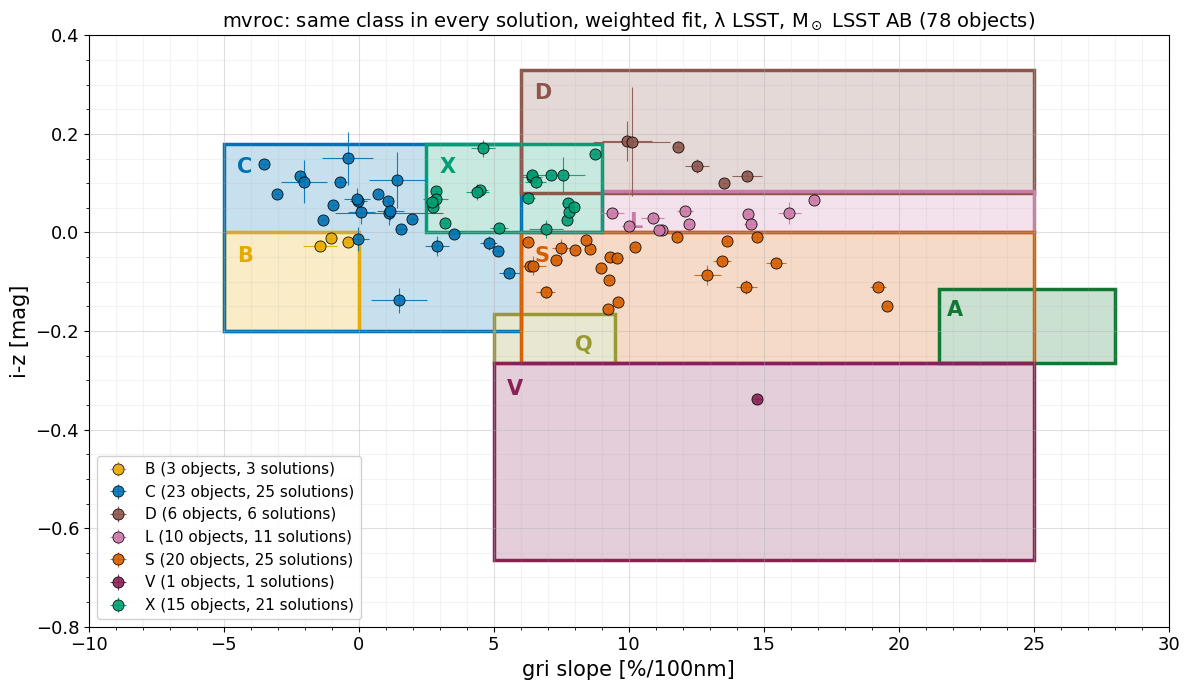

7 objects have at least one solution outside every box (unclassified)


In [3]:
cons_ids_cf = objs_cf.loc[objs_cf['consistent'], 'provid']
cons_cf = sol_cf[sol_cf['provid'].isin(cons_ids_cf)]
outside_cf = sorted(sol_cf.loc[sol_cf['taxonomy_lsst'] == tx.UNCLASSIFIED, 'provid'].unique())

fig, ax = plt.subplots(figsize=(12, 7))
tx.plot_taxonomy([], ax=ax, legend=False)
for label in sorted(cons_cf['taxonomy_lsst'].unique()):
    g = cons_cf[cons_cf['taxonomy_lsst'] == label]
    ax.errorbar(g['slope_lsst'], g['i_z'], xerr=g['slope_lsst_err'], yerr=g['i_z_err'],
                fmt='o', ms=8, color=colors[label], mec='k', mew=0.6, elinewidth=0.8, alpha=0.9,
                label=f"{label} ({g['provid'].nunique()} objects, {len(g)} solutions)", zorder=4)
ax.set_title(f'mvroc: same class in every solution, weighted fit, λ LSST, M$_\\odot$ LSST AB '
             f'({len(cons_ids_cf)} objects)', fontsize=14)
ax.legend(loc='lower left', fontsize=11, framealpha=0.9)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_MV_CF, '_overview_taxonomy_consistent.png'), dpi=150)
plt.show()
print(f'{len(outside_cf)} objects have at least one solution outside every box (unclassified)')

### 1.2 One figure per object, all its solutions

Top: taxonomy diagram with the LSST slope and i−z of each solution and their 1σ error bars; the legend gives
slope, i−z and class. Bottom: reflectances $R_g, R_r, R_i$ with their errors at the LSST wavelengths and the weighted
linear fit of each solution (one colour per solution, points shifted slightly in λ so they do not overlap);
the legend gives the slope and the χ² of the fit.
Files: `<FIG_DIR_MV_CF>/<provid>_solutions.png`.

103 figures saved in figures/taxonomy_mvroc/


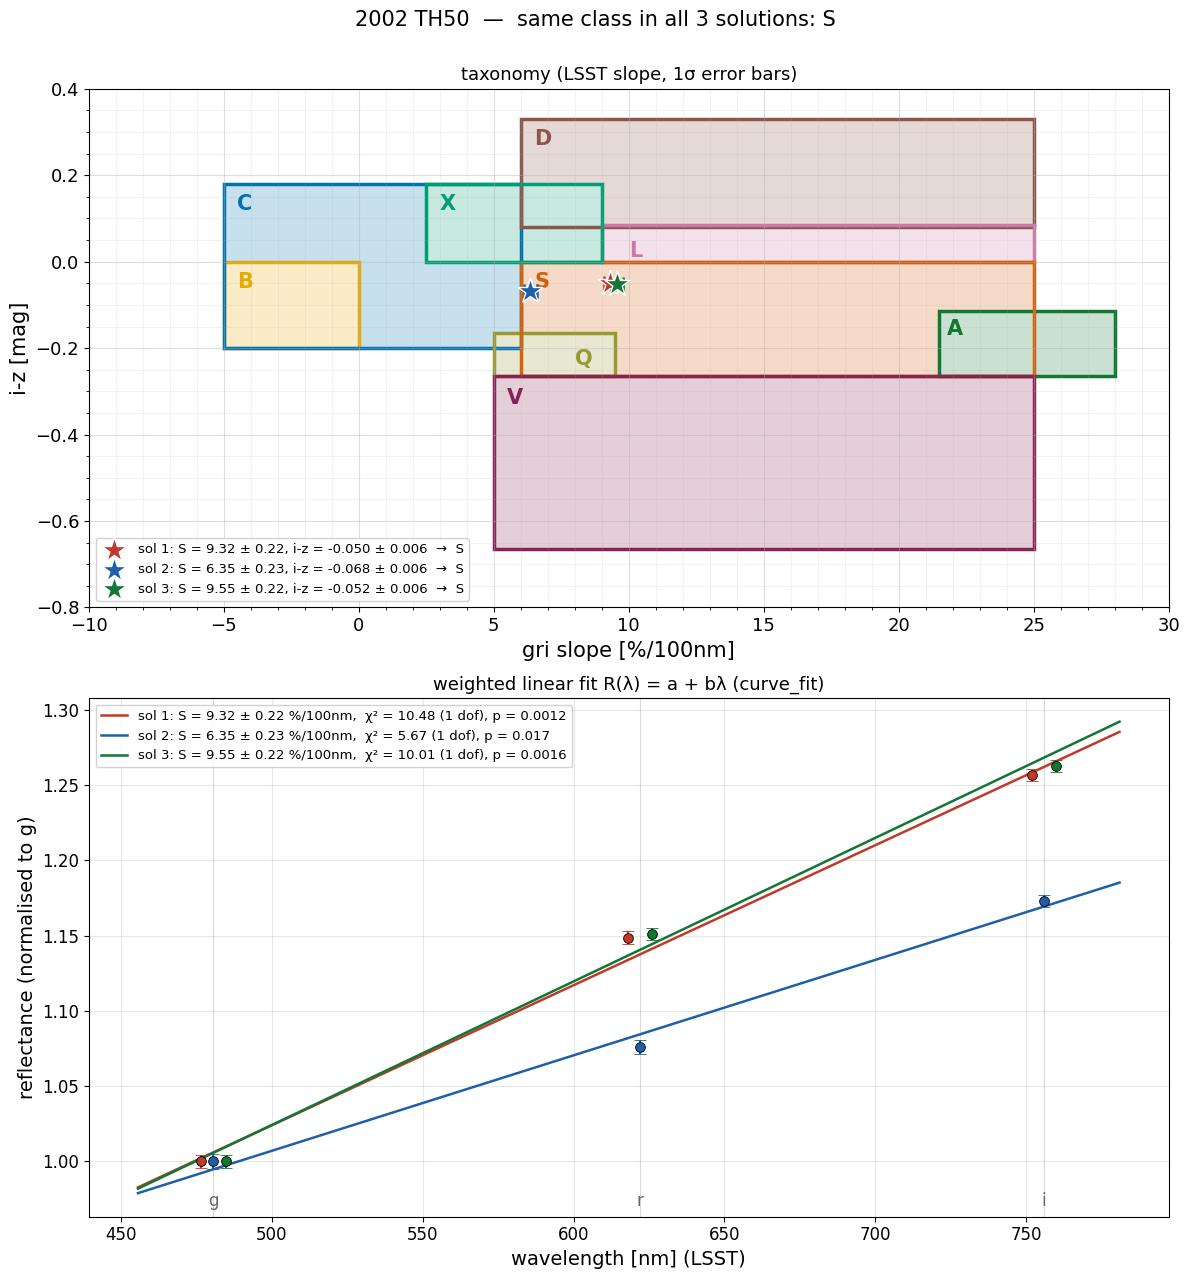

In [4]:
for provid in objs_cf['provid']:
    fig, axes = plot_solutions(provid, out_dir=FIG_DIR_MV_CF, sol_df=sol_cf, objs_df=objs_cf)
    plt.close(fig)
print(f'{len(objs_cf)} figures saved in {FIG_DIR_MV_CF}/')

example = multi_cf['provid'].iloc[0] if len(multi_cf) else objs_cf['provid'].iloc[0]
fig, axes = plot_solutions(example, sol_df=sol_cf, objs_df=objs_cf)
plt.show()

## 2. Mean H per band (`H_promedio_por_objeto.parquet`): weighted linear fit of the reflectances, LSST

For every object with g, r, i and z:

1. Reflectances from the mean H of each band, LSST AB solar magnitudes, normalised to g
   (`tx.gri_reflectances`): $R_f = 10^{-0.4[(H_f - H_g) - (M_{f,\odot} - M_{g,\odot})]}$.
2. Reflectance errors by error propagation from the H error of the same band (`H_*_err_scaled`):
   $\sigma_{R_f} = 0.4\ln 10\, R_f\, \sigma_{H_f}$. $H_g$ only sets the normalisation, so the three points are
   independent and $R_g = 1 \pm 0.4\ln10\,\sigma_{H_g}$.
3. Straight line $R(\lambda) = a + b\lambda$ at the LSST wavelengths with `scipy.optimize.curve_fit`
   (`tx.gri_slope_fit`), `sigma` = reflectance errors, `absolute_sigma=True`; the wavelengths are taken as exact.
   The slope and intercept errors come from the fit covariance; gri slope $= 10^4 b$ [%/100nm].
4. $\chi^2 = \sum_k [(R_k - a - b\lambda_k)/\sigma_{R_k}]^2$ with 3 − 2 = 1 degree of freedom.

i−z = $H_i - H_z$. Figures and tables go to `figures/taxonomy_jpl/`.

In [5]:
HPROM = 'data/H_promedio_por_objeto.parquet'
FIG_DIR_HP = 'figures/taxonomy_jpl'
os.makedirs(FIG_DIR_HP, exist_ok=True)

hp = pd.read_parquet(HPROM)
hp4 = hp[hp[[f'H_L{b}_mean' for b in 'griz']].notna().all(axis=1)].reset_index(drop=True)

hp_tax = pd.DataFrame({'provid': hp4['object_id'].astype(str), 'solution_id': 1})
for b in 'griz':
    hp_tax[f'H_{b}'] = hp4[f'H_L{b}_mean']
    hp_tax[f'H_{b}_err'] = hp4[f'H_L{b}_err_scaled']
    hp_tax[f'N_{b}'] = hp4[f'N_L{b}']
for c1, c2 in [('g', 'r'), ('r', 'i'), ('i', 'z')]:
    hp_tax[f'{c1}-{c2}'] = hp_tax[f'H_{c1}'] - hp_tax[f'H_{c2}']
    hp_tax[f'{c1}-{c2}_err'] = np.hypot(hp_tax[f'H_{c1}_err'], hp_tax[f'H_{c2}_err'])

# 1-2. reflectances and their errors
R = tx.gri_reflectances(hp_tax['H_g'], hp_tax['H_r'], hp_tax['H_i'],
                        hp_tax['H_g_err'], hp_tax['H_r_err'], hp_tax['H_i_err'], m_sun=tx.M_SUN_LSST)
hp_tax = pd.concat([hp_tax, R], axis=1)

# 3-4. weighted fit, one per object
fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
hp_tax['slope_lsst'] = fit['slope']
hp_tax['slope_lsst_err'] = fit['slope_err']
hp_tax['intercept'] = fit['intercept']
hp_tax['intercept_err'] = fit['intercept_err']
hp_tax['cov_ab'] = fit['cov_ab']
hp_tax['chi2'] = fit['chi2']
hp_tax['ndof'] = fit['ndof']
hp_tax['p_value'] = fit['p_value']
hp_tax['i_z'] = hp_tax['i-z']
hp_tax['i_z_err'] = hp_tax['i-z_err']

res = tx.classify_catalogue(hp_tax['slope_lsst'], hp_tax['i_z'], hp_tax['slope_lsst_err'], hp_tax['i_z_err'])
hp_tax['taxonomy_lsst'] = res['taxonomy']
hp_tax['p_class_lsst'] = res['p_class']
hp_tax['candidates_lsst'] = res['candidates']

print(f'{len(hp)} objects in {HPROM}; with g, r, i and z: {len(hp_tax)}')
print(hp_tax['taxonomy_lsst'].value_counts().to_string())
print(f"chi2 (1 dof): median {hp_tax['chi2'].median():.2f}; chi2 > 3.84 (p < 0.05): "
      f"{(hp_tax['chi2'] > 3.84).mean():.0%} of the objects")

fit_cols = ['provid', 'solution_id', 'R_g', 'R_g_err', 'R_r', 'R_r_err', 'R_i', 'R_i_err',
            'slope_lsst', 'slope_lsst_err', 'intercept', 'intercept_err', 'cov_ab', 'chi2', 'ndof', 'p_value',
            'i_z', 'i_z_err', 'taxonomy_lsst', 'p_class_lsst', 'candidates_lsst']
hp_fit_params = hp_tax[fit_cols]
hp_tax.to_csv(os.path.join(FIG_DIR_HP, 'taxonomy_jpl.csv'), index=False)
hp_fit_params.to_csv(os.path.join(FIG_DIR_HP, 'fit_jpl.csv'), index=False)
hp_fit_params.head(10).round(4)

9432 objects in data/H_promedio_por_objeto.parquet; with g, r, i and z: 3168
taxonomy_lsst
indeterminate    875
unclassified     541
S                512
C                469
X                421
D                164
L                103
V                 44
B                 37
Q                  1
A                  1
chi2 (1 dof): median 4.54; chi2 > 3.84 (p < 0.05): 53% of the objects


,provid,solution_id,R_g,R_g_err,R_r,R_r_err,R_i,R_i_err,slope_lsst,slope_lsst_err,...,intercept_err,cov_ab,chi2,ndof,p_value,i_z,i_z_err,taxonomy_lsst,p_class_lsst,candidates_lsst
0,2016 GC22,1,1.0,0.0056,1.1243,0.0098,1.1689,0.0054,6.1383,0.2841,...,0.0180,-0.0050,12.5298,1,0.0004,-0.0547,0.0133,S,0.6427,S 0.64 / C 0.36
1,2026 DD30,1,1.0,0.0097,1.0933,0.0197,1.0623,0.0094,2.2618,0.4891,...,0.0311,-0.0149,8.6795,1,0.0032,0.0388,0.0153,C,0.6687,C 0.67 / X 0.33
2,2026 DB30,1,1.0,0.0052,1.0452,0.0055,1.0277,0.0033,0.7867,0.2190,...,0.0148,-0.0032,24.3514,1,0.0000,0.0654,0.0082,C,1.0000,C 1.00
3,2026 DK30,1,1.0,0.0059,1.0961,0.0059,1.1832,0.0036,6.6395,0.2445,...,0.0166,-0.0040,0.0835,1,0.7725,0.0054,0.0102,X,0.6459,X 0.65 / S 0.34
4,2026 DZ29,1,1.0,0.0120,1.0349,0.0196,1.0713,0.0081,2.5952,0.5228,...,0.0353,-0.0182,0.0065,1,0.9357,0.0216,0.0256,indeterminate,0.5596,C 0.56 / X 0.44
5,2026 DY30,1,1.0,0.0107,1.1864,0.0124,1.1036,0.0091,3.4309,0.5094,...,0.0330,-0.0165,87.7964,1,0.0000,0.1087,0.0139,X,0.9514,X 0.95
6,2026 DQ29,1,1.0,0.0033,0.9899,0.0041,0.9650,0.0022,-1.3076,0.1428,...,0.0096,-0.0014,2.9258,1,0.0872,0.0579,0.0062,C,1.0000,C 1.00
7,2026 DA30,1,1.0,0.0073,1.0893,0.0056,1.1831,0.0049,6.7008,0.3125,...,0.0207,-0.0064,0.4621,1,0.4967,0.0298,0.0119,X,0.9712,X 0.97
8,2026 DO29,1,1.0,0.0061,1.0958,0.0054,1.1636,0.0039,5.8364,0.2579,...,0.0173,-0.0044,3.2932,1,0.0696,0.0669,0.0107,X,1.0000,X 1.00
9,2026 DG29,1,1.0,0.0203,1.0729,0.0128,1.0389,0.0127,0.6717,0.8332,...,0.0552,-0.0455,9.2417,1,0.0024,-0.0068,0.0169,C,0.8544,C 0.85 / B 0.14


### 2.1 Overview (weighted fit, LSST)

All classified objects (box letter or indeterminate); objects outside every box are not drawn.

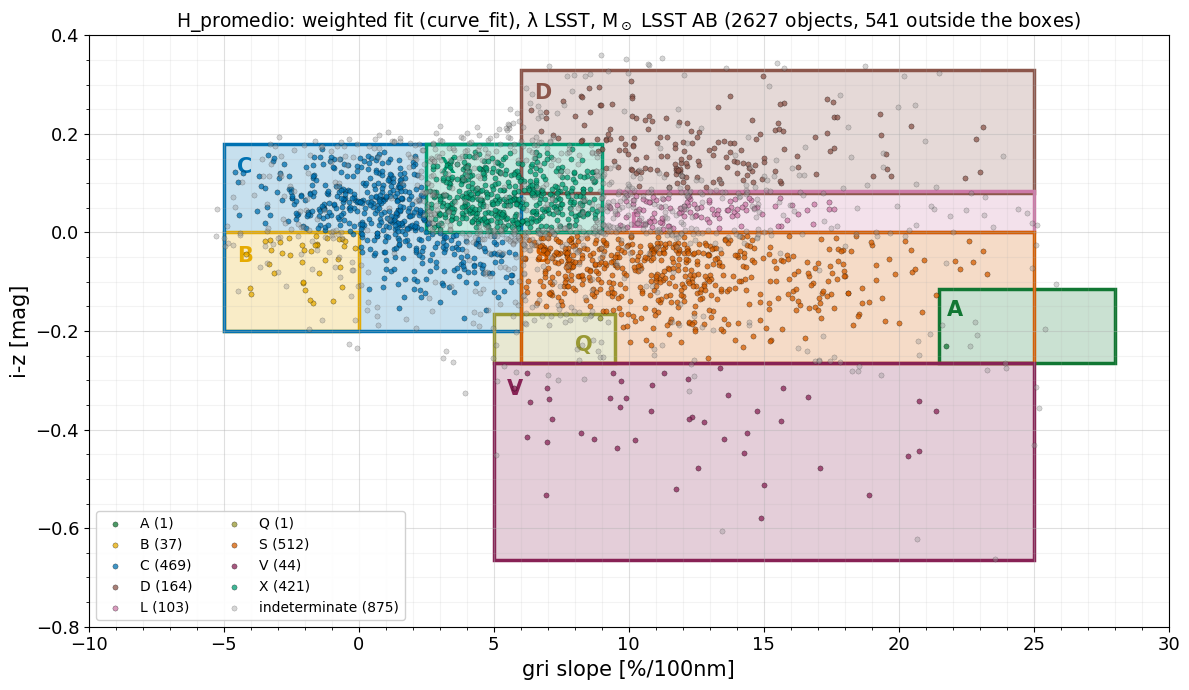

In [6]:
sel_hp = hp_tax[hp_tax['taxonomy_lsst'] != tx.UNCLASSIFIED]
fig, ax = plt.subplots(figsize=(12, 7))
tx.plot_taxonomy([], ax=ax, legend=False)
order = sorted(sel_hp['taxonomy_lsst'].unique(), key=lambda c: (c == tx.INDETERMINATE, c))
for label in order:
    g = sel_hp[sel_hp['taxonomy_lsst'] == label]
    ax.scatter(g['slope_lsst'], g['i_z'], s=14, color=colors[label], edgecolors='k', linewidths=0.25,
               alpha=0.75 if label != tx.INDETERMINATE else 0.4, label=f'{label} ({len(g)})', zorder=4)
n_out = (hp_tax['taxonomy_lsst'] == tx.UNCLASSIFIED).sum()
ax.set_title(f'H_promedio: weighted fit (curve_fit), λ LSST, M$_\\odot$ LSST AB '
             f'({len(sel_hp)} objects, {n_out} outside the boxes)', fontsize=13.5)
ax.legend(loc='lower left', fontsize=10, framealpha=0.9, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_HP, '_overview_taxonomy.png'), dpi=150)
plt.show()

### Fit quality

Left: χ² of every fit against the χ² distribution with 1 degree of freedom. Right: slope error vs slope.

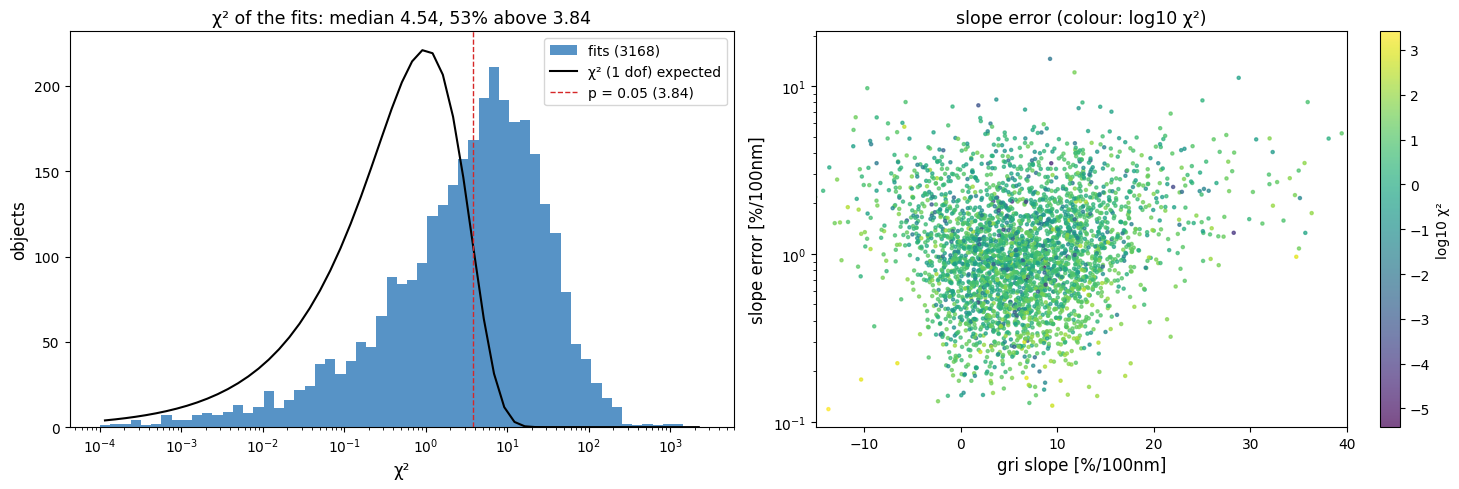

In [7]:
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
c2 = hp_tax['chi2'].dropna()
bins = np.logspace(np.log10(max(c2.min(), 1e-4)), np.log10(c2.max()), 60)
ax.hist(c2, bins=bins, color='#1f6fb4', alpha=0.75, label=f'fits ({len(c2)})')
centers = np.sqrt(bins[1:] * bins[:-1])
ax.plot(centers, len(c2) * np.diff(stats.chi2.cdf(bins, 1)), 'k-', lw=1.5, label='χ² (1 dof) expected')
ax.axvline(3.84, color='#d62728', ls='--', lw=1, label='p = 0.05 (3.84)')
ax.set_xscale('log')
ax.set_xlabel('χ²', fontsize=12)
ax.set_ylabel('objects', fontsize=12)
ax.set_title(f"χ² of the fits: median {c2.median():.2f}, {(c2 > 3.84).mean():.0%} above 3.84", fontsize=12.5)
ax.legend(fontsize=10)

ax = axes[1]
ax.scatter(hp_tax['slope_lsst'], hp_tax['slope_lsst_err'], s=5, c=np.log10(hp_tax['chi2']), cmap='viridis', alpha=0.7)
ax.set_yscale('log')
ax.set_xlim(-15, 40)
ax.set_xlabel('gri slope [%/100nm]', fontsize=12)
ax.set_ylabel('slope error [%/100nm]', fontsize=12)
ax.set_title('slope error (colour: log10 χ²)', fontsize=12.5)
fig.colorbar(ax.collections[0], ax=ax, label='log10 χ²')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR_HP, '_fit_chi2.png'), dpi=150)
plt.show()

### 2.2 Selected objects

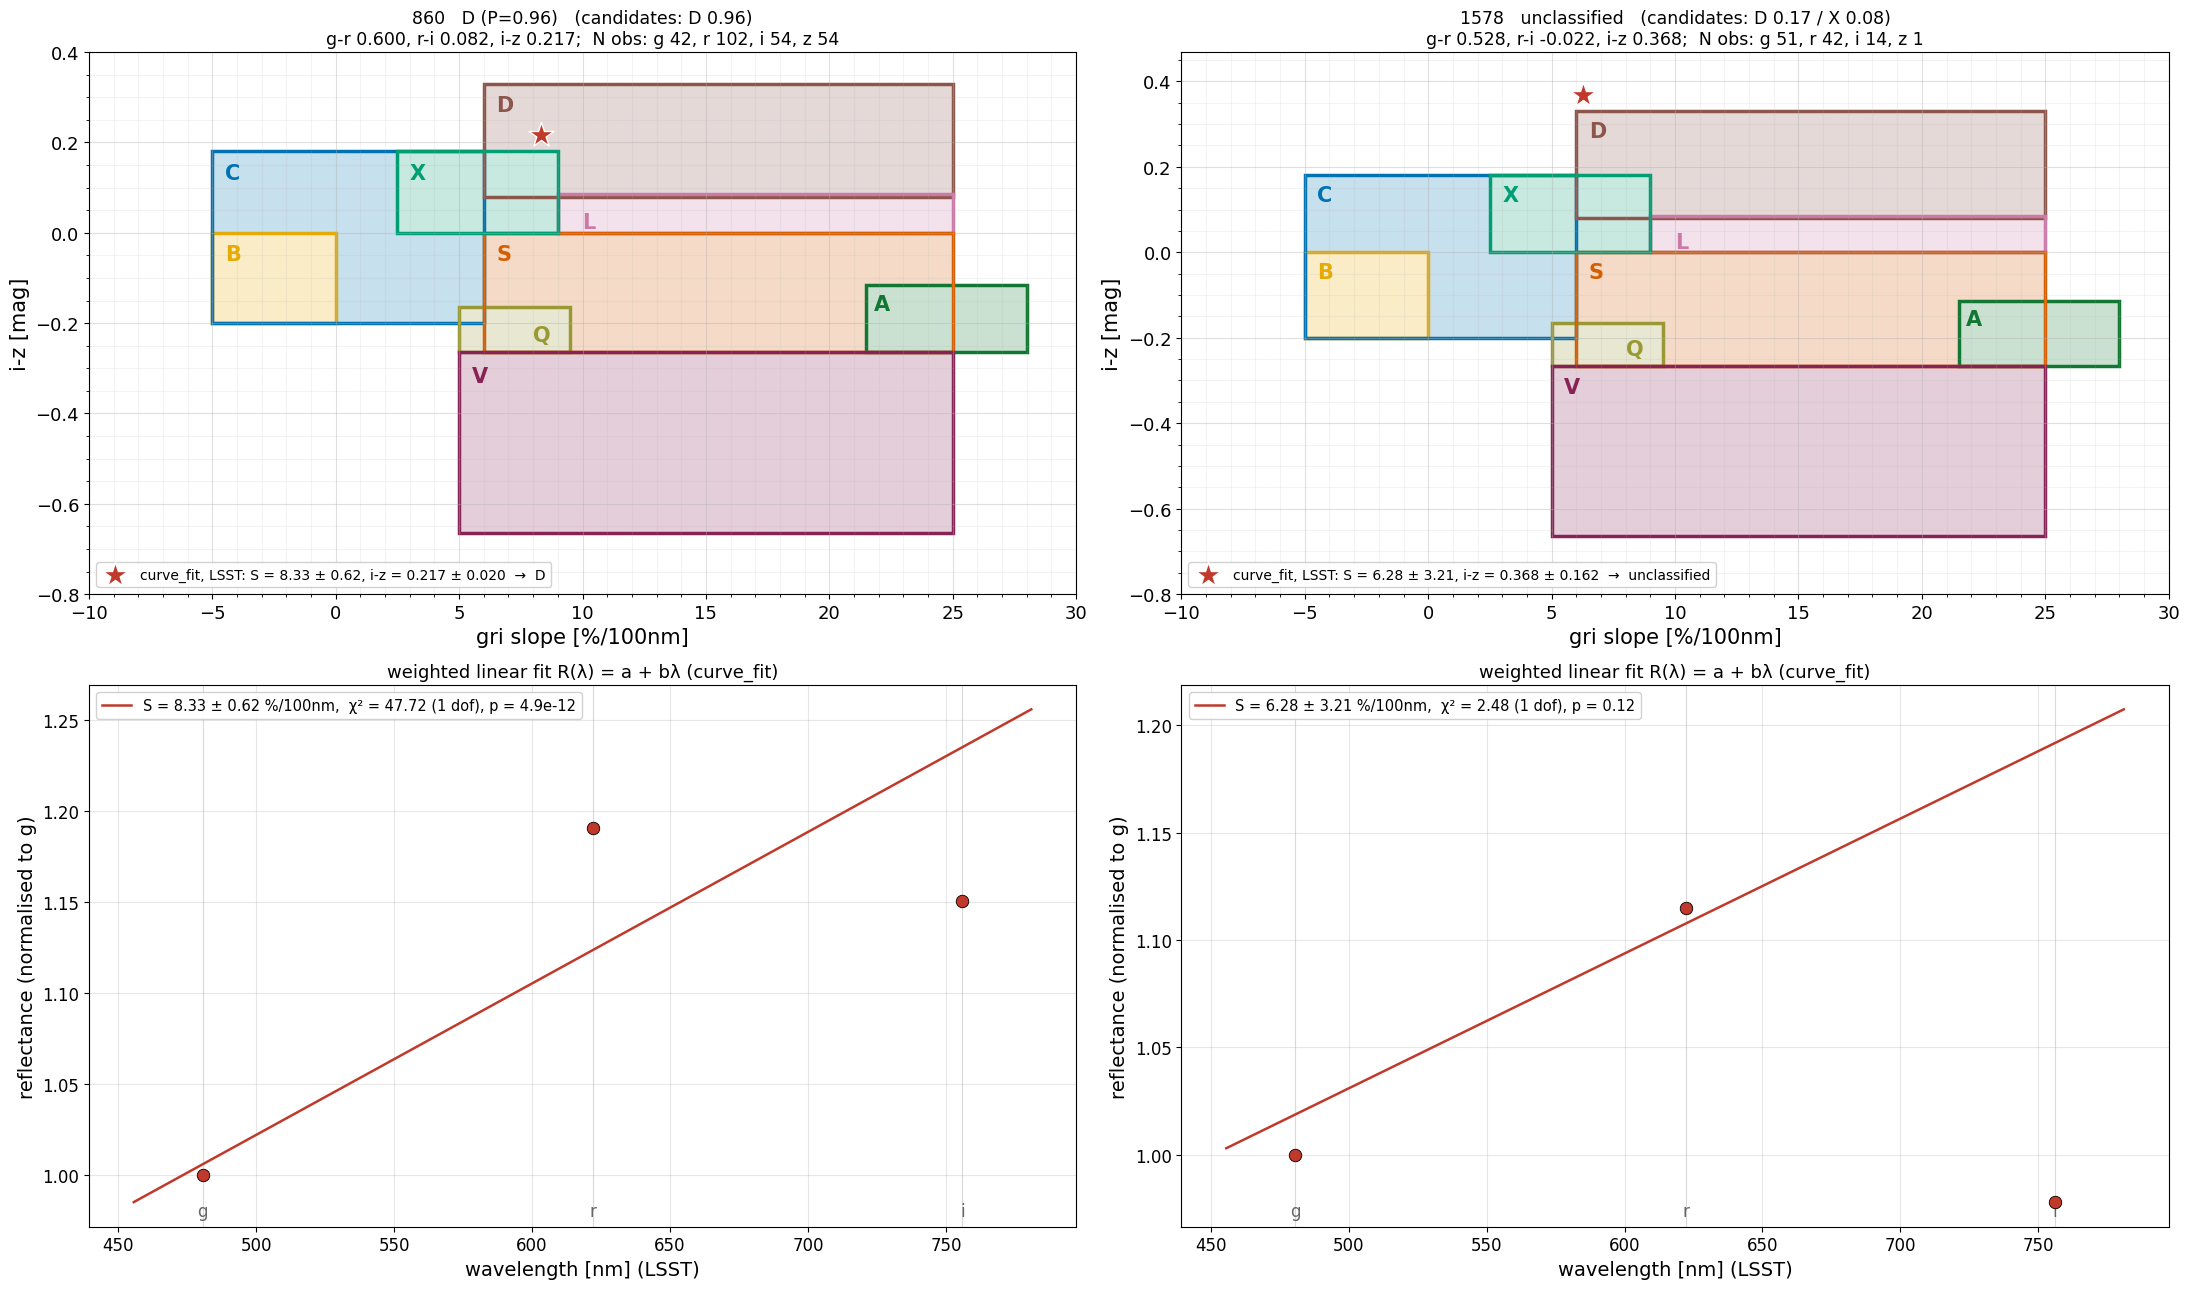

In [8]:
def plot_hp_objects(ids, fname=None):
    # one column per object: taxonomy on top, reflectances and their weighted linear fit below (no error bars)
    fig, axes = plt.subplots(2, len(ids), figsize=(11 * len(ids), 13), squeeze=False)
    lam = np.array([tx.LAM_LSST[b] for b in 'gri'])
    lam_line = np.linspace(lam.min() - 25, lam.max() + 25, 50)
    for k, oid in enumerate(ids):
        ax, axf = axes[0, k], axes[1, k]
        r = hp_tax[hp_tax['provid'] == str(oid)].iloc[0]
        nobs = ', '.join(f"{b} {r[f'N_{b}']}" for b in 'griz')
        point = dict(label=f"curve_fit, LSST: S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f}, "
                           f"i-z = {r['i_z']:.3f} ± {r['i_z_err']:.3f}  →  {r['taxonomy_lsst']}",
                     slope=r['slope_lsst'], iz=r['i_z'], color='#C0392B')
        tx.plot_taxonomy([point], ax=ax)
        ax.set_title(f"{oid}   {class_label(r, 'lsst')}   (candidates: {r['candidates_lsst'] or '-'})\n"
                     f"g-r {r['g-r']:.3f}, r-i {r['r-i']:.3f}, i-z {r['i-z']:.3f};  N obs: {nobs}", fontsize=12.5)
        ax.legend(loc='lower left', fontsize=10, framealpha=0.9)

        R = np.array([r[f'R_{b}'] for b in 'gri'])
        axf.plot(lam, R, 'o', ms=9, color='#C0392B', mec='k', mew=0.6, zorder=5)
        axf.plot(lam_line, r['intercept'] + r['slope_lsst'] / 1e4 * lam_line, '-', color='#C0392B', lw=1.8,
                 label=f"S = {r['slope_lsst']:.2f} ± {r['slope_lsst_err']:.2f} %/100nm,  "
                       f"χ² = {r['chi2']:.2f} ({int(r['ndof'])} dof), p = {r['p_value']:.2g}")
        for b, l in zip('gri', lam):
            axf.axvline(l, color='0.85', lw=0.8, zorder=0)
            axf.text(l, 0.02, b, transform=axf.get_xaxis_transform(), ha='center', fontsize=12, color='0.4')
        axf.set_xlabel('wavelength [nm] (LSST)', fontsize=14)
        axf.set_ylabel('reflectance (normalised to g)', fontsize=14)
        axf.tick_params(labelsize=12)
        axf.grid(alpha=0.3)
        axf.legend(loc='upper left', fontsize=10.5, framealpha=0.9)
        axf.set_title('weighted linear fit R(λ) = a + bλ (curve_fit)', fontsize=13)
    fig.tight_layout()
    if fname:
        fig.savefig(os.path.join(FIG_DIR_HP, fname), dpi=150)
    return fig, axes


fig, axes = plot_hp_objects(['860', '1578'], fname='860_1578_taxonomy.png')
plt.show()